# ЛР №3 — герметичний конвеєр і чесна валідація (Quality Gate 3)

| Розділ | Пункт ТЗ |
|---|---|
| 1. DVC-лінідж | 4.1 |
| 2. Механізм витоку ЛР №2 (теорія) | 4.2, ч. 1 |
| 3. Герметичний конвеєр і доказ, що жоден fit не бачить test | 4.3 |
| 4. Вибір ланки: детектор чи ресемплер | 4.3 |
| 5. Вкладена CV: результати по фолдах | 4.4 |
| 6. Аудиторський слід імпутера по фолдах | 4.4 |
| 7. Cost-sensitive: таблиця трьох підходів і графік втрат | 4.5 |
| 8. Статистична перевірка різниці (McNemar) — **останньою** | 4.2, ч. 3 |


In [1]:
import sys, os, json, hashlib, warnings, subprocess
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "4")
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "evaluation.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, joblib, yaml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

from src.data import load_dataset, read_csv, pointer_md5
from src.evaluation import (load_config, build_hermetic_pipeline, fold_metrics, fairness_by_fold, cost_curve,
                            threshold_grid, total_cost, pooled_predictions, SELECT_STEPS)

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ART, FIG = ROOT / "artifacts", ROOT / "artifacts" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "text.color": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.axisbelow": True})

CFG = {"LR": ROOT / "config/config_lr.yaml", "RF": ROOT / "config/config_rf.yaml"}
cfg = load_config(CFG["LR"]); COSTS = cfg["costs"]; FAIR = cfg["fairness"]
X, y = load_dataset()
group = X[FAIR["attribute"]].to_numpy()
RES = {(m, v): joblib.load(ART / "nested" / f"{m.lower()}_{v}.joblib")
       for m in ("LR", "RF") for v in ("base", "cs", "nosmote")}
def ms(s): return f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"

## 1. DVC-лінідж (п. 4.1)


In [2]:
rows = []
for name in ("german_credit_mcar.csv", "lab2_feature_matrix.csv", "lab2_test_predictions.csv"):
    actual = hashlib.md5((ROOT / "data/raw" / name).read_bytes()).hexdigest()
    rows.append({"файл": name, "md5 у .dvc": pointer_md5(name), "md5 файлу": actual, "збіг": actual == pointer_md5(name)})
display(pd.DataFrame(rows))
print((ROOT / "data/raw/lab2_feature_matrix.csv.dvc").read_text())
print(subprocess.run([str(ROOT / ".venv/bin/dvc"), "status"], cwd=ROOT, capture_output=True, text=True).stdout)
print("X:", X.shape, "| частка bad (міноритарний клас):", y.mean().round(3))

,файл,md5 у .dvc,md5 файлу,збіг
0,german_credit_mcar.csv,8e4f9757e3fe506cb0eae2804fec1026,8e4f9757e3fe506cb0eae2804fec1026,True
1,lab2_feature_matrix.csv,c6cfcbbe784ee2407a235ddb309f9736,c6cfcbbe784ee2407a235ddb309f9736,True
2,lab2_test_predictions.csv,f74d98141d8d5bb72295aa10e558732c,f74d98141d8d5bb72295aa10e558732c,True


outs:
- md5: c6cfcbbe784ee2407a235ddb309f9736
  size: 3646549
  hash: md5
  path: lab2_feature_matrix.csv


Data and pipelines are up to date.


X:

(1000, 172)

| частка bad (міноритарний клас):

0.3

## 2. Механізм витоку ЛР №2 (п. 4.2, частина 1)


In [3]:
lab2 = read_csv("lab2_test_predictions.csv", index_col=0)
lab2_auc = {c: roc_auc_score(lab2["y_test"], lab2[c]) for c in lab2.columns if c.startswith(("3.", "4."))}
pd.Series(lab2_auc, name="ROC-AUC (ЛР №2, test 300)").round(4).to_frame()

,"ROC-AUC (ЛР №2, test 300)"
3. Extracted + AutoFE [LR],0.7605
3. Extracted + AutoFE [RF],0.7568
4. Leaky Pipeline [LR],0.8606
4. Leaky Pipeline [RF],0.8161


## 3. Герметичний конвеєр (п. 4.3)


In [4]:
pipe = build_hermetic_pipeline(CFG["LR"])
for name, step in pipe.steps:
    print(f"{name:9s} {type(step).__module__.split('.')[0]:>12s}.{type(step).__name__}")

prep           sklearn.ColumnTransformer

basic     lab02_selection.CorrelationFilter

filter         sklearn.SelectKBest

wrapper        mlxtend.SequentialFeatureSelector

embedded       sklearn.SelectFromModel

resample      imblearn.SMOTE

model          sklearn.LogisticRegression

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.evaluation import FitSpy, FIT_LOG
outer = StratifiedKFold(**cfg["cv"]["outer"]); inner = StratifiedKFold(**cfg["cv"]["inner"])
tr, te = next(outer.split(X, y))
FIT_LOG.pop("demo", None)
spy_pipe = build_hermetic_pipeline(CFG["LR"], spy=FitSpy("demo"))
cross_val_predict(spy_pipe, X.iloc[tr], y[tr], cv=inner, method="predict_proba")
test_rows = set(X.index[te])
for k, ((itr, iva), seen) in enumerate(zip(inner.split(X.iloc[tr], y[tr]), FIT_LOG["demo"])):
    print(f"внутрішній фолд {k}: fit бачив {len(seen)} рядків; з них у валідації внутрішнього фолду — "
          f"{len(seen & set(X.index[tr][iva]))}, у зовнішньому test — {len(seen & test_rows)}")

внутрішній фолд 0: fit бачив 533 рядків; з них у валідації внутрішнього фолду — 0, у зовнішньому test — 0

внутрішній фолд 1: fit бачив 533 рядків; з них у валідації внутрішнього фолду — 0, у зовнішньому test — 0

внутрішній фолд 2: fit бачив 534 рядків; з них у валідації внутрішнього фолду — 0, у зовнішньому test — 0

## 4. Вибір ланки: детектор аномалій чи ресемплер (п. 4.3)


In [6]:
from sklearn.ensemble import IsolationForest
from src.preprocessor import DynamicPipelineBuilder
prep = DynamicPipelineBuilder(str(CFG["LR"])).build()
Z = prep.fit_transform(X.iloc[tr], y[tr])
anom = IsolationForest(contamination=0.05, random_state=42).fit(Z).predict(Z) == -1
ytr, gtr = y[tr], group[tr]
pd.DataFrame({
    "аномалій": [int(anom.sum())],
    "частка bad серед аномалій": [ytr[anom].mean()], "частка bad загалом": [ytr.mean()],
    "позначено чоловіків": [anom[gtr == "male"].mean()], "позначено жінок": [anom[gtr == "female"].mean()],
}).round(3)

,аномалій,частка bad серед аномалій,частка bad загалом,позначено чоловіків,позначено жінок
0,40,0.175,0.3,0.06,0.028


## 5. Вкладена крос-валідація (п. 4.4)


In [7]:
summary = []
for (m, v), res in RES.items():
    for thr in (("0.5",) if v != "cs" else ("0.5", "inner")):
        fm = fold_metrics(res, COSTS, threshold=thr)
        summary.append({"модель": m, "варіант": v, "поріг": "0.5" if thr == "0.5" else "T (внутр. OOF)",
                        "ROC-AUC": ms(fm.roc_auc), "F1": ms(fm.f1), "втрати DM / заявку": ms(fm.cost_per_applicant),
                        "inner AUC": ms(pd.Series([r["inner_best_auc"] for r in res]))})
pd.DataFrame(summary)

,модель,варіант,поріг,ROC-AUC,F1,втрати DM / заявку,inner AUC
0,LR,base,0.5,0.746 ± 0.034,0.574 ± 0.043,170.850 ± 16.159,0.759 ± 0.009
1,LR,cs,0.5,0.742 ± 0.030,0.480 ± 0.010,100.500 ± 5.712,0.758 ± 0.010
2,LR,cs,T (внутр. OOF),0.742 ± 0.030,0.484 ± 0.012,103.050 ± 11.995,0.758 ± 0.010
3,LR,nosmote,0.5,0.750 ± 0.033,0.472 ± 0.049,285.000 ± 27.326,0.758 ± 0.012
4,RF,base,0.5,0.750 ± 0.051,0.559 ± 0.070,193.800 ± 35.803,0.748 ± 0.011
5,RF,cs,0.5,0.745 ± 0.042,0.481 ± 0.012,100.200 ± 3.990,0.740 ± 0.015
6,RF,cs,T (внутр. OOF),0.745 ± 0.042,0.486 ± 0.006,99.450 ± 6.130,0.740 ± 0.015
7,RF,nosmote,0.5,0.744 ± 0.036,0.340 ± 0.105,347.100 ± 46.015,0.750 ± 0.012


In [8]:
bp = []
for m in ("LR", "RF"):
    for r in RES[(m, "base")]:
        bp.append({"модель": m, "фолд": r["fold"], **{k: (round(v, 5) if isinstance(v, float) else v) for k, v in r["best_params"].items()},
                   "inner AUC": round(r["inner_best_auc"], 4), "outer AUC": round(r["test_auc"], 4), "ознак після відбору": len(r["selected_features"])})
best_params = pd.DataFrame(bp); best_params.to_csv(ART / "best_params_base.csv", index=False)
best_params

,модель,фолд,filter__k,resample__k_neighbors,model__C,model__l1_ratio,inner AUC,outer AUC,ознак після відбору,model__n_estimators,model__max_depth
0,LR,0,22,3,84.34957,1.0,0.7505,0.7348,12,NaN,NaN
1,LR,1,20,4,0.16962,1.0,0.7700,0.7399,8,NaN,NaN
2,LR,2,31,5,0.82885,1.0,0.7573,0.7415,9,NaN,NaN
3,LR,3,20,10,2.36165,0.0,0.7490,0.8037,6,NaN,NaN
4,LR,4,36,9,0.20363,1.0,0.7659,0.7110,9,NaN,NaN
5,RF,0,33,3,NaN,NaN,0.7407,0.7922,11,179.0,3.0
6,RF,1,21,4,NaN,NaN,0.7620,0.7106,9,247.0,4.0
7,RF,2,25,4,NaN,NaN,0.7574,0.7557,10,340.0,4.0
8,RF,3,37,6,NaN,NaN,0.7352,0.8053,10,100.0,4.0
9,RF,4,31,5,NaN,NaN,0.7454,0.6871,9,316.0,4.0


In [9]:
from collections import Counter
cnt = Counter(f.split("__", 1)[1] for r in RES[("LR", "base")] for f in r["selected_features"])
stab = pd.Series(cnt).sort_values(ascending=False).rename("фолдів (з 5)")
stab.to_csv(ART / "selection_stability_lr.csv")
stab.head(20).to_frame()

,фолдів (з 5)
duration_div_age,5
checking_account,5
credit_history,5
purpose,4
duration,4
property,3
MAX_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT,3
duration_div_MEAN_payments_AMT_INSTALMENT,3
installment_rate,3
savings_account,2


## 6. Аудиторський слід імпутера по фолдах (п. 4.4)
і.

In [10]:
audit = pd.concat([r["imputer_audit"] for r in RES[("LR", "base")]])
audit["правило"] = audit["strategy"] + audit["add_indicator"].map({True: " +I", False: ""})
shares = audit.pivot(index="feature", columns="fold", values="missing_share")
rules = audit.pivot(index="feature", columns="fold", values="правило")
cols = ["credit_amount", "age", "residence_since", "employment_since", "purpose", "savings_account", "job", "complaint_text", "sig_zcr", "COUNT_payments"]
view = shares.loc[cols].round(4).astype(str) + " · " + rules.loc[cols]
view.columns = [f"фолд {c}" for c in view.columns]
audit.to_csv(ART / "imputer_audit_folds.csv", index=False)
print("колонок, де правило відрізняється між фолдами:", int((rules.nunique(axis=1) > 1).sum()),
      "| де відрізняється частка:", int((shares.nunique(axis=1) > 1).sum()), "з", len(shares))
view

колонок, де правило відрізняється між фолдами:

0

| де відрізняється частка:

148

з

165

,фолд 0,фолд 1,фолд 2,фолд 3,фолд 4
feature,,,,,
credit_amount,0.1988 · median +I,0.1925 · median +I,0.2025 · median +I,0.2025 · median +I,0.2037 · median +I
age,0.0488 · median,0.055 · median,0.0488 · median,0.0475 · median,0.05 · median
residence_since,0.5038 · constant +I,0.4988 · constant +I,0.5012 · constant +I,0.4988 · constant +I,0.4975 · constant +I
employment_since,0.1487 · constant,0.1475 · constant,0.1512 · constant,0.155 · constant,0.1475 · constant
purpose,0.2625 · constant,0.2412 · constant,0.25 · constant,0.2587 · constant,0.2375 · constant
savings_account,0.055 · most_frequent,0.0587 · most_frequent,0.06 · most_frequent,0.0638 · most_frequent,0.0625 · most_frequent
job,0.0275 · most_frequent,0.0312 · most_frequent,0.0288 · most_frequent,0.0288 · most_frequent,0.0338 · most_frequent
complaint_text,0.0 · constant,0.0 · constant,0.0 · constant,0.0 · constant,0.0 · constant
sig_zcr,0.0238 · median,0.02 · median,0.02 · median,0.015 · median,0.0262 · median


In [11]:
import tempfile
demo_cfg = load_config(CFG["LR"])
demo_cfg["imputation_policy"]["categorical"][0]["max_share"] = 0.25
f = tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False, encoding="utf-8"); yaml.safe_dump(demo_cfg, f, allow_unicode=True); f.close()
demo = []
for k, (tr_k, _) in enumerate(outer.split(X, y)):
    ct = DynamicPipelineBuilder(f.name).build().fit(X.iloc[tr_k], y[tr_k])
    a = DynamicPipelineBuilder.audit_trail(ct).set_index("feature").loc["purpose"]
    demo.append({"фолд": k, "частка пропусків purpose": round(a.missing_share, 4), "правило": f"≤{a.max_share}: {a.strategy}", "заповнення": a.fill_value})
pd.DataFrame(demo)

,фолд,частка пропусків purpose,правило,заповнення
0,0,0.2625,≤1.0: constant,Missing
1,1,0.2412,≤0.25: most_frequent,radio/television
2,2,0.2500,≤0.25: most_frequent,radio/television
3,3,0.2587,≤1.0: constant,Missing
4,4,0.2375,≤0.25: most_frequent,radio/television


## 7. Cost-sensitive навчання й поріг (п. 4.5)


In [12]:
three = []
for m in ("LR", "RF"):
    for label, v, thr in (("Baseline (без зважування, поріг 0.5)", "base", "0.5"),
                          ("Cost-Sensitive (class_weight), поріг 0.5", "cs", "0.5"),
                          ("Cost-Sensitive + оптимальний поріг T", "cs", "inner"),
                          ("(додатково) без зважування + оптимальний T", "base", "inner")):
        fm = fold_metrics(RES[(m, v)], COSTS, threshold=thr)
        three.append({"модель": m, "підхід": label, "сумарні втрати, DM (5 фолдів)": int(fm.cost_total.sum()),
                      "DM / заявку": ms(fm.cost_per_applicant), "F1": ms(fm.f1), "ROC-AUC": ms(fm.roc_auc),
                      "поріг": ms(fm.threshold) if thr == "inner" else "0.5"})
three = pd.DataFrame(three); three.to_csv(ART / "three_approaches.csv", index=False)
trivial = {"усім видати": 0.3 * COSTS["C10"], "усім відмовити": 0.7 * COSTS["C01"]}
print("тривіальні політики, DM / заявку:", trivial)
three

тривіальні політики, DM / заявку:

{'усім видати': 450.0, 'усім відмовити': 105.0}

,модель,підхід,"сумарні втрати, DM (5 фолдів)",DM / заявку,F1,ROC-AUC,поріг
0,LR,"Baseline (без зважування, поріг 0.5)",170850,170.850 ± 16.159,0.574 ± 0.043,0.746 ± 0.034,0.5
1,LR,"Cost-Sensitive (class_weight), поріг 0.5",100500,100.500 ± 5.712,0.480 ± 0.010,0.742 ± 0.030,0.5
2,LR,Cost-Sensitive + оптимальний поріг T,103050,103.050 ± 11.995,0.484 ± 0.012,0.742 ± 0.030,0.550 ± 0.050
3,LR,(додатково) без зважування + оптимальний T,109650,109.650 ± 22.917,0.493 ± 0.018,0.746 ± 0.034,0.153 ± 0.070
4,RF,"Baseline (без зважування, поріг 0.5)",193800,193.800 ± 35.803,0.559 ± 0.070,0.750 ± 0.051,0.5
5,RF,"Cost-Sensitive (class_weight), поріг 0.5",100200,100.200 ± 3.990,0.481 ± 0.012,0.745 ± 0.042,0.5
6,RF,Cost-Sensitive + оптимальний поріг T,99450,99.450 ± 6.130,0.486 ± 0.006,0.745 ± 0.042,0.529 ± 0.067
7,RF,(додатково) без зважування + оптимальний T,105900,105.900 ± 18.850,0.492 ± 0.024,0.750 ± 0.051,0.131 ± 0.047


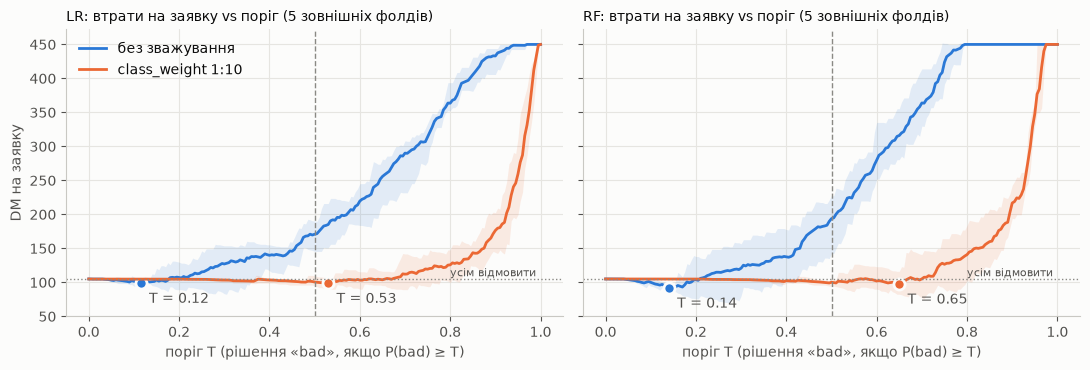

T* середньої кривої (описово; на тих самих фолдах — оптимістично):

{'LR/base': np.float64(0.115), 'LR/cs': np.float64(0.53), 'RF/base': np.float64(0.14), 'RF/cs': np.float64(0.65)}

In [13]:
grid = threshold_grid(COSTS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
T_star = {}
for ax, m in zip(axes, ("LR", "RF")):
    for v, color, label in (("base", BLUE, "без зважування"), ("cs", ORANGE, "class_weight 1:10")):
        curves = np.array([cost_curve(r["y_test"], r["p_test"], COSTS) for r in RES[(m, v)]])
        mean = curves.mean(0)
        ax.plot(grid, mean, color=color, lw=2, label=label)
        ax.fill_between(grid, curves.min(0), curves.max(0), color=color, alpha=0.12, lw=0)
        t = grid[np.argmin(mean)]; T_star[(m, v)] = t
        ax.plot([t], [mean.min()], "o", color=color, ms=8, mec="#fcfcfb", mew=2)
        ax.annotate(f"T = {t:.2f}", (t, mean.min()), textcoords="offset points", xytext=(6, -14), color="#52514e")
    ax.axvline(0.5, color=GRAY, ls="--", lw=1)
    ax.axhline(trivial["усім відмовити"], color=GRAY, ls=":", lw=1)
    ax.text(0.99, trivial["усім відмовити"] + 4, "усім відмовити", ha="right", color="#52514e", fontsize=8)
    ax.set_title(f"{m}: втрати на заявку vs поріг (5 зовнішніх фолдів)", loc="left", fontsize=10)
    ax.set_xlabel("поріг T (рішення «bad», якщо P(bad) ≥ T)")
axes[0].set_ylabel("DM на заявку"); axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "cost_vs_threshold.png", dpi=130); plt.show()
print("T* середньої кривої (описово; на тих самих фолдах — оптимістично):", {f"{m}/{v}": round(t, 3) for (m, v), t in T_star.items()})

In [14]:
pd.DataFrame({m: [round(r["threshold"], 3) for r in RES[(m, "cs")]] for m in ("LR", "RF")},
             index=[f"фолд {k}" for k in range(5)]).T.assign(середнє=lambda d: d.mean(axis=1).round(3))

,фолд 0,фолд 1,фолд 2,фолд 3,фолд 4,середнє
LR,0.62,0.485,0.57,0.530,0.545,0.550
RF,0.59,0.515,0.42,0.575,0.545,0.529


### Вибір фінальної моделі (REFORMS 5d)


In [15]:
final_cost = {m: fold_metrics(RES[(m, "cs")], COSTS, "inner").cost_per_applicant.mean() for m in ("LR", "RF")}
FINAL = min(final_cost, key=final_cost.get)
print({m: round(c, 1) for m, c in final_cost.items()}, "→ фінальна модель:", FINAL)

{'LR': np.float64(103.0), 'RF': np.float64(99.4)}

→ фінальна модель:

RF

## 8. Статистична перевірка різниці (п. 4.2, частина 3) — виконується останньою


In [16]:
from mlxtend.evaluate import mcnemar, mcnemar_table
test_idx = lab2.index.to_numpy(); train_idx = np.setdiff1d(np.arange(len(X)), test_idx)
assert (lab2["y_test"].to_numpy() == y[test_idx]).all()
clean_p = {}
for m in ("LR", "RF"):
    params = {"model__l1_ratio": 0.0, "model__C": 1.0} if m == "LR" else {}
    p = build_hermetic_pipeline(CFG[m], resample=False, params=params).fit(X.iloc[train_idx], y[train_idx])
    clean_p[m] = p.predict_proba(X.iloc[test_idx])[:, 1]

def mcnemar_row(name, y_true, p1, p2):
    a, b = (p1 >= 0.5).astype(int), (p2 >= 0.5).astype(int)
    tb = mcnemar_table(y_target=y_true, y_model1=a, y_model2=b)
    chi2, p = mcnemar(ary=tb, corrected=True)
    return {"порівняння": name, "AUC 1": roc_auc_score(y_true, p1), "AUC 2": roc_auc_score(y_true, p2),
            "accuracy 1": (a == y_true).mean(), "accuracy 2": (b == y_true).mean(),
            "b: помиляється лише 1": int(tb[1, 0]), "c: помиляється лише 2": int(tb[0, 1]), "χ²": chi2, "p-value": p}

yt = lab2["y_test"].to_numpy()
rows = []
for m in ("LR", "RF"):
    rows.append(mcnemar_row(f"{m}: чистий (ЛР №3) vs Експ. 4 ЛР №2 (витік)", yt, clean_p[m], lab2[f"4. Leaky Pipeline [{m}]"].to_numpy()))
    rows.append(mcnemar_row(f"{m}: Експ. 3 ЛР №2 vs Експ. 4 ЛР №2 (довідково)", yt, lab2[f"3. Extracted + AutoFE [{m}]"].to_numpy(), lab2[f"4. Leaky Pipeline [{m}]"].to_numpy()))
    nested = pooled_predictions(RES[(m, "base")], len(X))[test_idx]
    rows.append(mcnemar_row(f"{m}: вкладена CV ЛР №3 (OOF) vs Експ. 4 ЛР №2", yt, nested, lab2[f"4. Leaky Pipeline [{m}]"].to_numpy()))
mc = pd.DataFrame(rows); mc.to_csv(ART / "mcnemar.csv", index=False)
mc.round(4)

,порівняння,AUC 1,AUC 2,accuracy 1,accuracy 2,b: помиляється лише 1,c: помиляється лише 2,χ²,p-value
0,LR: чистий (ЛР №3) vs Експ. 4 ЛР №2 (витік),0.7731,0.8606,0.7667,0.8200,34,18,4.3269,0.0375
1,LR: Експ. 3 ЛР №2 vs Експ. 4 ЛР №2 (довідково),0.7605,0.8606,0.7433,0.8200,43,20,7.6825,0.0056
2,LR: вкладена CV ЛР №3 (OOF) vs Експ. 4 ЛР №2,0.7668,0.8606,0.7000,0.8200,59,23,14.9390,0.0001
3,RF: чистий (ЛР №3) vs Експ. 4 ЛР №2 (витік),0.7161,0.8161,0.7067,0.7867,45,21,8.0152,0.0046
4,RF: Експ. 3 ЛР №2 vs Експ. 4 ЛР №2 (довідково),0.7568,0.8161,0.7333,0.7867,40,24,3.5156,0.0608
5,RF: вкладена CV ЛР №3 (OOF) vs Експ. 4 ЛР №2,0.7374,0.8161,0.7033,0.7867,53,28,7.1111,0.0077


In [17]:
summary = {
    "final_model": FINAL, "final_cost_per_applicant": final_cost,
    "T_star_mean_curve": {f"{m}/{v}": float(t) for (m, v), t in T_star.items()},
    "thresholds_inner": {m: [r["threshold"] for r in RES[(m, "cs")]] for m in ("LR", "RF")},
    "lab2_auc": lab2_auc, "clean_auc": {m: roc_auc_score(yt, clean_p[m]) for m in clean_p},
}
(ART / "summary_robust.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(summary, indent=1, ensure_ascii=False, default=float)[:1500])

{
 "final_model": "RF",
 "final_cost_per_applicant": {
  "LR": 103.05,
  "RF": 99.45
 },
 "T_star_mean_curve": {
  "LR/base": 0.115,
  "LR/cs": 0.53,
  "RF/base": 0.14,
  "RF/cs": 0.65
 },
 "thresholds_inner": {
  "LR": [
   0.62,
   0.485,
   0.5700000000000001,
   0.53,
   0.545
  ],
  "RF": [
   0.59,
   0.515,
   0.42,
   0.5750000000000001,
   0.545
  ]
 },
 "lab2_auc": {
  "3. Extracted + AutoFE [LR]": 0.7604761904761904,
  "3. Extracted + AutoFE [RF]": 0.7567989417989419,
  "4. Leaky Pipeline [LR]": 0.8606349206349206,
  "4. Leaky Pipeline [RF]": 0.8160846560846562
 },
 "clean_auc": {
  "LR": 0.773068783068783,
  "RF": 0.7161375661375662
 }
}